# CS4085 Deep Learning — Lab 6: Car Detection with YOLO
**Dr. Naila Marir · Effat College of Engineering**
**Student version**

---

## 🚗 The Project

You are on the engineering team of a self-driving car. A camera is mounted on the front of the car and takes a photo of the road every few seconds. Your job in this lab is to build the **perception module**: a program that looks at one photo and answers *"What objects are in front of me, and where exactly are they?"*

**Deliverable:** a function `predict(image_file)` that takes a dash-cam photo and returns a short list of detected objects (car, bus, traffic light, …), each with a **bounding box** and a **confidence score**, drawn on the image.

We will use **YOLO** ("You Only Look Once"), a deep CNN that detects objects in a single forward pass. Training YOLO takes days on large GPUs, so we use **pre-trained weights** (YOLOv2, trained on the 80-class COCO dataset). Your work is the part that turns the raw network output into clean, usable detections.

### Project steps
| Step | What you build | Concept |
|---|---|---|
| 0 | Set up the workspace | — |
| 1 | Read the YOLO output tensor | Grid cells, anchor boxes, the 19×19×5×85 encoding |
| 2 | `yolo_filter_boxes` (Exercise 1) | Class score = $p_c \times c_i$, score thresholding |
| 3 | `iou` (Exercise 2) | Intersection over Union |
| 4 | `yolo_non_max_suppression` (Exercise 3) | Non-max suppression |
| 5 | `yolo_eval` (Exercise 4) | The full filtering pipeline |
| 6 | Run the pre-trained YOLO on a road image | From raw output to boxes on the picture |
| 7 | Tune and test your detector | Effect of the two thresholds |

**By the end of this lab you will be able to:** explain how YOLO encodes detections, implement score filtering, IoU and non-max suppression, and run a complete object-detection pipeline on real road images.

---
## Step 0 — Set up the workspace

This lab runs in **Google Colab** and needs only this notebook plus one folder in your Google Drive:

```
My Drive/ML_Labs/Lab6/
├── model_data/        ← pre-trained YOLOv2 model (saved_model.pb + variables/)
├── images/            ← road photos, e.g. test.jpg
└── out/               ← created automatically; detections are saved here
```

Run the cell below to connect to your Drive. If your folder is somewhere else, change `LAB_DIR`.

In [3]:
%pip install tensorflow numpy matplotlib pillow

In [7]:
import os, sys

# Connect Google Drive (only needed in Colab)
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

LAB_DIR   = "/content/drive/MyDrive/dl labs/lab6"
MODEL_DIR = os.path.join(LAB_DIR, "model_data")
IMAGE_DIR = os.path.join(LAB_DIR, "images")
OUT_DIR   = os.path.join(LAB_DIR, "out")
os.makedirs(OUT_DIR, exist_ok=True)

for p in [MODEL_DIR, IMAGE_DIR]:
    print(("✅ found   " if os.path.exists(p) else "❌ MISSING ") + p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ found   /content/drive/MyDrive/dl labs/lab6/model_data
✅ found   /content/drive/MyDrive/dl labs/lab6/images


Now load the packages. Everything used in this lab is standard (TensorFlow, NumPy, Matplotlib, Pillow) — no extra files to install.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import colorsys, random
from PIL import Image, ImageDraw, ImageFont
import tensorflow as tf

%matplotlib inline
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


---
## Step 1 — Read the YOLO output tensor

### Inputs and outputs
- **Input:** a batch of images of shape $(m, 608, 608, 3)$.
- **Output:** a list of boxes. Each box is described by $(p_c, b_x, b_y, b_h, b_w, c)$:
  - $p_c$ — probability that there is *some* object in the box
  - $(b_x, b_y)$ — the box centre, $(b_h, b_w)$ — its height and width
  - $c$ — the class. With 80 classes we write $c$ as 80 class probabilities $(c_1, \dots, c_{80})$, so each box is **5 + 80 = 85 numbers**.

### Grid cells and anchor boxes
- YOLO divides the image into a **19 × 19 grid**. If the **centre** of an object falls inside a grid cell, that cell is responsible for detecting it.
- Each cell predicts **5 boxes**, one per **anchor box**. An anchor is a typical box shape (width/height ratio) chosen from the training data — e.g. a wide anchor for cars, a tall one for pedestrians.

So the architecture is:

$$\text{IMAGE } (m, 608, 608, 3) \;\rightarrow\; \text{DEEP CNN} \;\rightarrow\; \text{ENCODING } (m, 19, 19, 5, 85)$$

The last two dimensions are often flattened: $5 \times 85 = 425$, so the CNN output is $(m, 19, 19, 425)$.

In total YOLO proposes $19 \times 19 \times 5 = 1805$ boxes from **one** forward pass. Most are useless — Steps 2–4 throw them away.

Run the cell below to see the encoding on a fake output and to split it into its parts.

In [9]:
# A fake CNN output for ONE image: 19 x 19 grid, 425 numbers per cell
fake_output = tf.random.normal([19, 19, 425])

# Un-flatten: 425 = 5 anchors x 85 numbers
encoding = tf.reshape(fake_output, [19, 19, 5, 85])

box_confidence  = encoding[..., 0:1]   # p_c
box_xywh        = encoding[..., 1:5]   # b_x, b_y, b_h, b_w
box_class_probs = encoding[..., 5:]    # c_1 ... c_80

print("encoding        :", encoding.shape)
print("box_confidence  :", box_confidence.shape)
print("box coordinates :", box_xywh.shape)
print("box_class_probs :", box_class_probs.shape)
print("total boxes     :", 19 * 19 * 5)

encoding        : (19, 19, 5, 85)
box_confidence  : (19, 19, 5, 1)
box coordinates : (19, 19, 5, 4)
box_class_probs : (19, 19, 5, 80)
total boxes     : 1805


> **Note.** In the real pre-trained model the 85 numbers are stored in a slightly different order and must be passed through sigmoid / exp / softmax first. You do not need to worry about that now — a helper called `yolo_head` does it for you in Step 6.

**✔ Check yourself:** If YOLO used a 13 × 13 grid, 3 anchors and 20 classes, what would the shape of the encoding be?

---
## Step 2 — Keep only confident boxes (score thresholding)

### Class score
For every box, the **score for class $i$** is

$$\text{score}_{c,i} = p_c \times c_i$$

the probability that there *is* an object, times the probability that the object *is class $i$*.

**Example.** Box 1 has $p_c = 0.60$ and the probability that its object is a car (class 3) is $c_3 = 0.73$. Its car score is $0.60 \times 0.73 = 0.44$. If 0.44 is the largest of the 80 class scores for this box, the box gets **class = car, score = 0.44**.

### The filter
We then drop every box whose best score is below a **threshold** (e.g. 0.6). It is convenient to have three tensors:
- `box_confidence` — shape $(19, 19, 5, 1)$, contains $p_c$
- `boxes` — shape $(19, 19, 5, 4)$, the box coordinates
- `box_class_probs` — shape $(19, 19, 5, 80)$, contains $(c_1, \dots, c_{80})$

### Exercise 1 — `yolo_filter_boxes`
1. Compute `box_scores` = $p_c \times c$. Shapes $(19,19,5,1)$ and $(19,19,5,80)$ multiply by **broadcasting** into $(19,19,5,80)$.
2. For each box find the **index** of the best class (`tf.math.argmax`) and the **value** of the best score (`tf.math.reduce_max`). Use `axis=-1` (the last axis).
3. Build a boolean `filtering_mask` that is `True` where the best score is `>= threshold`.
4. Apply the mask with `tf.boolean_mask` to the scores, boxes and classes.

In [13]:
def yolo_filter_boxes(boxes, box_confidence, box_class_probs, threshold=.6):
    """Filters YOLO boxes by thresholding on object and class confidence.

    Arguments:
        boxes -- tensor of shape (19, 19, 5, 4)
        box_confidence -- tensor of shape (19, 19, 5, 1)
        box_class_probs -- tensor of shape (19, 19, 5, 80)
        threshold -- if the highest class score of a box is < threshold, the box is removed

    Returns:
        scores -- tensor of shape (None,), class score of each kept box
        boxes -- tensor of shape (None, 4), coordinates of each kept box
        classes -- tensor of shape (None,), class index of each kept box
    (None = the number of kept boxes, which depends on the threshold)
    """
    ### START CODE HERE
    # 1. Compute box scores (≈ 1 line)
    box_scores = box_confidence * box_class_probs

    # 2. Best class index and its score for every box
    box_classes = tf.math.argmax(box_scores, axis=-1)
    box_class_scores = tf.math.reduce_max(box_scores, axis=-1)

    # 3. Mask: True for the boxes to keep
    filtering_mask = box_class_scores >= threshold

    # 4. Apply the mask
    scores = tf.boolean_mask(box_class_scores, filtering_mask)
    boxes = tf.boolean_mask(boxes, filtering_mask)
    classes = tf.boolean_mask(box_classes, filtering_mask)
    ### END CODE HERE

    return scores, boxes, classes

In [14]:
# ---- Test Exercise 1 ----
rng = np.random.default_rng(4085)
t_boxes = tf.constant(rng.uniform(0, 1, (19, 19, 5, 4)), tf.float32)
t_conf  = tf.constant(rng.uniform(0, 1, (19, 19, 5, 1)), tf.float32)
t_probs = tf.nn.softmax(tf.constant(rng.normal(0, 3, (19, 19, 5, 80)), tf.float32))

scores, boxes, classes = yolo_filter_boxes(t_boxes, t_conf, t_probs, threshold=0.5)
print("scores.shape  =", scores.shape)
print("boxes.shape   =", boxes.shape)
print("classes.shape =", classes.shape)
print("scores[2]     =", scores[2].numpy())
print("classes[2]    =", classes[2].numpy())

assert tf.is_tensor(scores) and tf.is_tensor(boxes) and tf.is_tensor(classes), "Use TensorFlow functions"
assert scores.shape == (153,) and boxes.shape == (153, 4) and classes.shape == (153,), "Wrong shapes"
assert np.isclose(scores[2].numpy(), 0.525514, atol=1e-5), "Wrong score values"
assert classes[2].numpy() == 63, "Wrong class values"
assert float(tf.reduce_min(scores)) >= 0.5, "Some kept boxes are below the threshold"
print("\033[92m✅ All tests passed!")

scores.shape  = (153,)
boxes.shape   = (153, 4)
classes.shape = (153,)
scores[2]     = 0.52551436
classes[2]    = 63
✅ All tests passed!


**Expected output**
```
scores.shape  = (153,)
boxes.shape   = (153, 4)
classes.shape = (153,)
scores[2]     = 0.52551...
classes[2]    = 63
```

**✔ Check yourself:** What happens to the number of kept boxes if you raise the threshold from 0.5 to 0.9? Try it.

---
## Step 3 — Measure overlap: Intersection over Union (IoU)

Even after thresholding, the same car is usually detected by **several overlapping boxes**. To decide whether two boxes describe the same object, we measure how much they overlap:

$$\text{IoU}(A, B) = \frac{\text{area}(A \cap B)}{\text{area}(A \cup B)} = \frac{\text{intersection}}{\text{area}(A) + \text{area}(B) - \text{intersection}}$$

IoU = 1 means the two boxes are identical; IoU = 0 means they do not touch.

**Conventions for this exercise**
- The origin $(0,0)$ is the **top-left** corner of the image; $x$ grows to the right, $y$ grows **down**.
- A box is given by its two corners: top-left $(x_1, y_1)$ and bottom-right $(x_2, y_2)$.
- Area of a box = $(x_2 - x_1) \times (y_2 - y_1)$.

Run the cell below to see two boxes and their intersection.

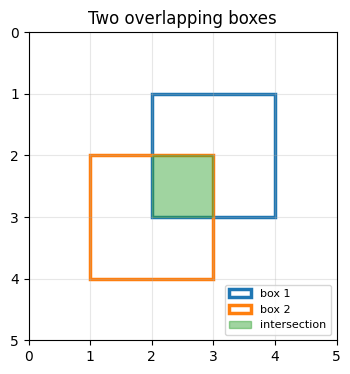

In [15]:
def show_two_boxes(box1, box2, title=""):
    """Draws two boxes (x1, y1, x2, y2) and shades their intersection."""
    fig, ax = plt.subplots(figsize=(4, 4))
    for b, col, name in [(box1, "tab:blue", "box 1"), (box2, "tab:orange", "box 2")]:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1],
                                       fill=False, lw=2.5, ec=col, label=name))
    xi1, yi1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    xi2, yi2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    if xi2 > xi1 and yi2 > yi1:
        ax.add_patch(patches.Rectangle((xi1, yi1), xi2 - xi1, yi2 - yi1,
                                       color="tab:green", alpha=.45, label="intersection"))
    lo = min(box1[0], box2[0], box1[1], box2[1]) - 1
    hi = max(box1[2], box2[2], box1[3], box2[3]) + 1
    ax.set_xlim(lo, hi); ax.set_ylim(hi, lo)          # y axis points down
    ax.set_aspect("equal"); ax.grid(alpha=.3); ax.legend(loc="lower right", fontsize=8)
    ax.set_title(title); plt.show()

show_two_boxes((2, 1, 4, 3), (1, 2, 3, 4), "Two overlapping boxes")

### Exercise 2 — `iou`
1. The **intersection** box has corners:
   - `xi1` = **max** of the two $x_1$, `yi1` = **max** of the two $y_1$
   - `xi2` = **min** of the two $x_2$, `yi2` = **min** of the two $y_2$
2. Its width and height are `xi2 - xi1` and `yi2 - yi1`. If either is negative the boxes do not overlap, so use `max(..., 0)`. Boxes that only touch at an edge or a corner have intersection area 0.
3. Union = area(box1) + area(box2) − intersection.
4. IoU = intersection / union.

In [16]:
def iou(box1, box2):
    """Intersection over Union between box1 and box2.

    Arguments:
    box1 -- (box1_x1, box1_y1, box1_x2, box1_y2)
    box2 -- (box2_x1, box2_y1, box2_x2, box2_y2)
    """
    (box1_x1, box1_y1, box1_x2, box1_y2) = box1
    (box2_x1, box2_y1, box2_x2, box2_y2) = box2

    ### START CODE HERE
  # Intersection corners and area
    xi1 = max(box1_x1, box2_x1)
    yi1 = max(box1_y1, box2_y1)
    xi2 = min(box1_x2, box2_x2)
    yi2 = min(box1_y2, box2_y2)
    inter_width = max(xi2 - xi1, 0)
    inter_height = max(yi2 - yi1, 0)
    inter_area = inter_width * inter_height

    # Union area
    box1_area = (box1_x2 - box1_x1) * (box1_y2 - box1_y1)
    box2_area = (box2_x2 - box2_x1) * (box2_y2 - box2_y1)
    union_area = box1_area + box2_area - inter_area

    # IoU
    iou = inter_area / union_area
    ### END CODE HERE

    return iou

In [17]:
# ---- Test Exercise 2 ----
print("overlapping boxes      :", iou((2, 1, 4, 3), (1, 2, 3, 4)))
print("separate boxes         :", iou((1, 2, 3, 4), (5, 6, 7, 8)))
print("touch at a corner only :", iou((1, 1, 2, 2), (2, 2, 3, 3)))
print("touch at an edge only  :", iou((1, 1, 3, 3), (2, 3, 3, 4)))
print("identical boxes        :", iou((0, 0, 4, 2), (0, 0, 4, 2)))

assert np.isclose(iou((2, 1, 4, 3), (1, 2, 3, 4)), 1/7), "Wrong value for overlapping boxes"
assert iou((1, 2, 3, 4), (5, 6, 7, 8)) == 0, "Separate boxes must give 0"
assert iou((1, 1, 2, 2), (2, 2, 3, 3)) == 0, "Boxes touching at a corner must give 0"
assert iou((1, 1, 3, 3), (2, 3, 3, 4)) == 0, "Boxes touching at an edge must give 0"
assert np.isclose(iou((0, 0, 4, 2), (0, 0, 4, 2)), 1), "Identical boxes must give 1"
print("\033[92m✅ All tests passed!")

overlapping boxes      : 0.14285714285714285
separate boxes         : 0.0
touch at a corner only : 0.0
touch at an edge only  : 0.0
identical boxes        : 1.0
✅ All tests passed!


**Expected output**
```
overlapping boxes      : 0.14285714285714285
separate boxes         : 0.0
touch at a corner only : 0.0
touch at an edge only  : 0.0
identical boxes        : 1.0
```
**✔ Check yourself:** Work out the first case on paper. What are the intersection area and the union area?

---
## Step 4 — Keep one box per object: Non-Max Suppression (NMS)

Non-max suppression uses IoU to remove duplicate detections:

1. **Select** the box with the highest score.
2. **Compare** it with every other box of the **same class**, and remove those that overlap a lot (IoU ≥ `iou_threshold`).
3. **Repeat** with the next highest remaining box until every box has been either kept or removed.

Boxes of **different classes** never suppress each other: a person standing in front of a car keeps both boxes.

The cell below shows the idea on three overlapping detections of the same car.

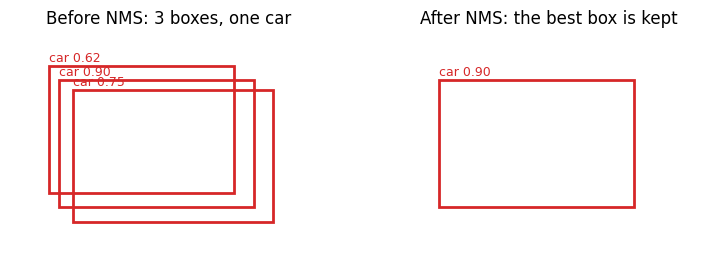

IoU of box 2 with the best box: 0.71
IoU of box 3 with the best box: 0.69


In [18]:
demo = [((1.0, 1.0, 5.0, 3.6), 0.90), ((1.3, 1.2, 5.4, 3.9), 0.75), ((0.8, 0.7, 4.6, 3.3), 0.62)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, kept, title in [(axes[0], demo, "Before NMS: 3 boxes, one car"),
                        (axes[1], demo[:1], "After NMS: the best box is kept")]:
    for (x1, y1, x2, y2), s in kept:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2, ec="tab:red"))
        ax.text(x1, y1 - .1, f"car {s:.2f}", color="tab:red", fontsize=9)
    ax.set_xlim(0, 6.5); ax.set_ylim(4.6, 0); ax.set_aspect("equal"); ax.set_title(title); ax.axis("off")
plt.show()
print("IoU of box 2 with the best box:", round(iou(demo[0][0], demo[1][0]), 2))
print("IoU of box 3 with the best box:", round(iou(demo[0][0], demo[2][0]), 2))

### Exercise 3 — `yolo_non_max_suppression`
TensorFlow already implements single-class NMS, so you will not call your `iou()` here. We apply it **class by class** (divide → suppress → merge):

- `tf.boolean_mask(tensor, mask)` — keep the elements where `mask` is True
- `tf.image.non_max_suppression(boxes, scores, max_output_size, iou_threshold)` — returns the **indices** of the boxes to keep
- `tf.gather(params, indices)` — pick elements by index
- `tf.concat(values, axis=0)` — join a list of tensors

For each class:
1. Get the boxes and scores of this class with `tf.boolean_mask`.
2. Run `tf.image.non_max_suppression` on them (`max_output_size=max_boxes`).
3. These indices are positions *inside the class subset*. `selected_indices` holds the original positions of that subset, so `tf.gather(selected_indices, nms_indices_label)` gives the original positions. Append them to `nms_indices`.

Then concatenate all classes and use `tf.gather` to select the kept scores, boxes and classes.

In [19]:
def yolo_non_max_suppression(scores, boxes, classes, max_boxes=10, iou_threshold=0.5):
    boxes = tf.cast(boxes, dtype=tf.float32)
    scores = tf.cast(scores, dtype=tf.float32)
    classes = tf.convert_to_tensor(classes)
    if tf.size(scores) == 0:
        return scores, boxes, classes

    nms_indices = []
    classes_labels = tf.unique(classes)[0]

    for label in classes_labels:
        filtering_mask = classes == label

        ### START CODE HERE
        # Boxes and scores of this class
        boxes_label = tf.boolean_mask(boxes, filtering_mask)
        scores_label = tf.boolean_mask(scores, filtering_mask)

        if tf.shape(scores_label)[0] > 0:
            # Indices (inside this class) of the boxes to keep
            nms_indices_label = tf.image.non_max_suppression(
                boxes_label, scores_label, max_boxes, iou_threshold=iou_threshold)

            # Original positions of this class's boxes (given)
            selected_indices = tf.squeeze(tf.where(filtering_mask), axis=1)

            # Map back to original positions and store
            nms_indices.append(tf.gather(selected_indices, nms_indices_label))

    # Join the indices of all classes
    nms_indices = tf.concat(nms_indices, axis=0)

    # Select the kept scores, boxes and classes
    scores = tf.gather(scores, nms_indices)
    boxes = tf.gather(boxes, nms_indices)
    classes = tf.gather(classes, nms_indices)
    ### END CODE HERE

    sort_order = tf.argsort(scores, direction="DESCENDING").numpy()
    scores = tf.gather(scores, sort_order[0:max_boxes])
    boxes = tf.gather(boxes, sort_order[0:max_boxes])
    classes = tf.gather(classes, sort_order[0:max_boxes])

    return scores, boxes, classes

In [20]:
# ---- Test Exercise 3 ----
# Case A: a car and a person that overlap -> different classes, both kept
sc = np.array([0.855, 0.828]); bx = np.array([[0.45, 0.2, 1.01, 2.6], [0.42, 0.15, 1.7, 1.01]])
s2, b2, c2 = yolo_non_max_suppression(sc, bx, np.array([0, 1]), iou_threshold=0.1)
assert np.allclose(s2.numpy(), [0.855, 0.828]) and np.array_equal(c2.numpy(), [0, 1]), "Different classes must never suppress each other"

# Case B: same two boxes, same class, low threshold -> only the best is kept
s2, b2, c2 = yolo_non_max_suppression(sc, bx, np.array([0, 0]), iou_threshold=0.15)
assert np.allclose(s2.numpy(), [0.855]) and np.allclose(b2.numpy(), [bx[0]]), "Overlapping boxes of the same class: keep only the best"

# Case C: same class, high threshold -> both kept
s2, b2, c2 = yolo_non_max_suppression(sc, bx, [0, 0], iou_threshold=0.9)
assert np.allclose(s2.numpy(), [0.855, 0.828]), "With a high IoU threshold both boxes stay"

# Case D: three detections of one car + one far-away car + one bus
sc = np.array([0.90, 0.75, 0.62, 0.80, 0.70])
bx = np.array([[1, 1, 3.6, 5], [1.2, 1.3, 3.9, 5.4], [0.7, 0.8, 3.3, 4.6],   # same car (y1, x1, y2, x2)
               [6, 6, 8, 9],                                               # another car
               [1, 1, 3.6, 5]])                                            # a bus at the same place
cl = np.array([2, 2, 2, 2, 5])
s2, b2, c2 = yolo_non_max_suppression(sc, bx, cl, max_boxes=10, iou_threshold=0.5)
print("Case D kept scores :", s2.numpy())
print("Case D kept classes:", c2.numpy())
assert np.allclose(s2.numpy(), [0.90, 0.80, 0.70]) and np.array_equal(c2.numpy(), [2, 2, 5]), "Case D failed"

# Case E: max_boxes limits the output
s2, _, _ = yolo_non_max_suppression(sc, bx, cl, max_boxes=2, iou_threshold=0.5)
assert s2.shape == (2,), "max_boxes is not respected"
print("\033[92m✅ All tests passed!")

Case D kept scores : [0.9 0.8 0.7]
Case D kept classes: [2 2 5]
✅ All tests passed!


**Expected output**
```
Case D kept scores : [0.9 0.8 0.7]
Case D kept classes: [2 2 5]
```
**✔ Check yourself:** In Case D, why is the bus box (score 0.70) kept even though it lies exactly on top of the best car box?

---
## Step 5 — Put the filters together: `yolo_eval`

Now chain everything into one function that turns the network output into final detections. Two given helpers are needed:

- `yolo_boxes_to_corners(box_xy, box_wh)` — YOLO predicts a box as *centre + size*. This converts it to *corners* $(y_1, x_1, y_2, x_2)$, the format NMS expects.
- `scale_boxes(boxes, image_shape)` — YOLO works with coordinates between 0 and 1 (relative to the 608 × 608 input). This multiplies them by the real image size (e.g. 720 × 1280) so the boxes can be drawn on the original photo.

In [21]:
def yolo_boxes_to_corners(box_xy, box_wh):
    """Convert YOLO (centre, size) boxes to corners (y_min, x_min, y_max, x_max)."""
    box_mins = box_xy - (box_wh / 2.)
    box_maxes = box_xy + (box_wh / 2.)
    return tf.concat([box_mins[..., 1:2],   # y_min
                      box_mins[..., 0:1],   # x_min
                      box_maxes[..., 1:2],  # y_max
                      box_maxes[..., 0:1]], # x_max
                     axis=-1)

def scale_boxes(boxes, image_shape):
    """Scale relative (0-1) box corners to pixel coordinates of an image of shape (height, width)."""
    height = float(image_shape[0])
    width = float(image_shape[1])
    image_dims = tf.reshape(tf.constant([height, width, height, width], tf.float32), [1, 4])
    return tf.cast(boxes, tf.float32) * image_dims

### Exercise 4 — `yolo_eval`
1. Unpack `yolo_outputs` into `box_xy, box_wh, box_confidence, box_class_probs`.
2. Convert to corners with `yolo_boxes_to_corners`.
3. Score-filter with your `yolo_filter_boxes` (`threshold=score_threshold`).
4. Rescale with `scale_boxes(boxes, image_shape)`.
5. Run your `yolo_non_max_suppression` with `max_boxes` and `iou_threshold`.

In [22]:
def yolo_eval(yolo_outputs, image_shape=(720, 1280), max_boxes=10, score_threshold=.6, iou_threshold=.5):
    """Converts the YOLO encoding (1805 boxes) into the final predicted boxes.

    Arguments:
    yolo_outputs -- 4 tensors: box_xy (.., 19, 19, 5, 2), box_wh (.., 19, 19, 5, 2),
                    box_confidence (.., 19, 19, 5, 1), box_class_probs (.., 19, 19, 5, 80)
    image_shape -- (height, width) of the original image
    max_boxes -- maximum number of boxes to return
    score_threshold -- minimum class score to keep a box
    iou_threshold -- IoU threshold used for NMS

    Returns:
    scores, boxes, classes -- the final detections
    """
    ### START CODE HERE
      # 1. Unpack the outputs
    box_xy, box_wh, box_confidence, box_class_probs = yolo_outputs

    # 2. Centre/size -> corners
    boxes = yolo_boxes_to_corners(box_xy, box_wh)

    # 3. Score filtering
    scores, boxes, classes = yolo_filter_boxes(boxes, box_confidence, box_class_probs, threshold=score_threshold)

    # 4. Scale boxes to the original image size
    boxes = scale_boxes(boxes, image_shape)

    # 5. Non-max suppression
    scores, boxes, classes = yolo_non_max_suppression(scores, boxes, classes, max_boxes, iou_threshold)
    ### END CODE HERE

    return scores, boxes, classes

In [23]:
# ---- Test Exercise 4 ----
rng = np.random.default_rng(608)
t_outputs = (tf.constant(rng.uniform(0, 1, (19, 19, 5, 2)), tf.float32),
             tf.constant(rng.uniform(0, .3, (19, 19, 5, 2)), tf.float32),
             tf.constant(rng.uniform(0, 1, (19, 19, 5, 1)), tf.float32),
             tf.nn.softmax(tf.constant(rng.normal(0, 3, (19, 19, 5, 80)), tf.float32)))
scores, boxes, classes = yolo_eval(t_outputs)
print("scores.shape =", scores.shape, "| boxes.shape =", boxes.shape, "| classes.shape =", classes.shape)
print("scores[2]    =", scores[2].numpy())
print("boxes[2]     =", boxes[2].numpy())
print("classes[2]   =", classes[2].numpy())

assert scores.shape == (10,) and boxes.shape == (10, 4) and classes.shape == (10,), "Wrong shapes"
assert np.isclose(scores[2].numpy(), 0.886589, atol=1e-5), "Wrong score values"
assert np.allclose(boxes[2].numpy(), [464.1488, 311.2583, 547.9338, 465.2929], atol=1e-2), "Wrong box values (did you scale the boxes?)"
assert classes[2].numpy() == 3, "Wrong class values"
print("\033[92m✅ All tests passed!")

scores.shape = (10,) | boxes.shape = (10, 4) | classes.shape = (10,)
scores[2]    = 0.8865893
boxes[2]     = [464.14883 311.25827 547.9338  465.29294]
classes[2]   = 3
✅ All tests passed!


**Expected output**
```
scores.shape = (10,) | boxes.shape = (10, 4) | classes.shape = (10,)
scores[2]    = 0.88659...
boxes[2]     = [464.15 311.26 547.93 465.29]
classes[2]   = 3
```

---
## Step 6 — Run the pre-trained YOLO on a real road image

Your filtering pipeline is ready. Now connect it to the real network:

```
image file ──preprocess──▶ (1, 608, 608, 3) ──YOLO CNN──▶ (1, 19, 19, 425)
           ──yolo_head──▶ box_xy, box_wh, box_confidence, box_class_probs
           ──yolo_eval (YOUR CODE)──▶ scores, boxes, classes ──▶ boxes drawn on the image
```

### 6.1 — Classes, anchors and image size
The model detects the **80 COCO classes** and uses **5 anchor boxes** (width, height in grid-cell units). They are written directly below, so no extra files are needed.

In [24]:
class_names = ["person", "bicycle", "car", "motorbike", "aeroplane", "bus", "train", "truck", "boat",
    "traffic light", "fire hydrant", "stop sign", "parking meter", "bench", "bird", "cat", "dog", "horse",
    "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "backpack", "umbrella", "handbag", "tie",
    "suitcase", "frisbee", "skis", "snowboard", "sports ball", "kite", "baseball bat", "baseball glove",
    "skateboard", "surfboard", "tennis racket", "bottle", "wine glass", "cup", "fork", "knife", "spoon",
    "bowl", "banana", "apple", "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut",
    "cake", "chair", "sofa", "pottedplant", "bed", "diningtable", "toilet", "tvmonitor", "laptop", "mouse",
    "remote", "keyboard", "cell phone", "microwave", "oven", "toaster", "sink", "refrigerator", "book",
    "clock", "vase", "scissors", "teddy bear", "hair drier", "toothbrush"]

# YOLOv2 COCO anchors: (width, height) of the 5 anchor boxes, in grid-cell units
anchors = np.array([[0.57273, 0.677385], [1.87446, 2.06253], [3.33843, 5.47434],
                    [7.88282, 3.52778], [9.77052, 9.16828]], dtype=np.float32)

model_image_size = (608, 608)
print(len(class_names), "classes |", len(anchors), "anchors")

80 classes | 5 anchors


### 6.2 — Load the pre-trained model
These weights are the official YOLOv2 weights converted to TensorFlow. The cell works with the TensorFlow version in Colab.

In [25]:
def load_yolo_model(path):
    """Loads the pre-trained YOLO model and returns a function image_batch -> (m, 19, 19, 425)."""
    try:                                                     # older Keras / .h5 file
        model = tf.keras.models.load_model(path, compile=False)
        print("Loaded with tf.keras")
        return model
    except Exception:                                        # Keras 3: load the TensorFlow SavedModel directly
        loaded = tf.saved_model.load(path)
        fn = loaded.signatures["serving_default"]
        in_name = list(fn.structured_input_signature[1].keys())[0]
        out_name = list(fn.structured_outputs.keys())[0]
        print("Loaded TensorFlow SavedModel | input:", fn.structured_input_signature[1][in_name].shape,
              "| output:", fn.structured_outputs[out_name].shape)
        def model(x):
            return fn(**{in_name: tf.convert_to_tensor(x, tf.float32)})[out_name]
        model._loaded = loaded                                  # keep a reference
        return model

yolo_model = load_yolo_model(MODEL_DIR)

Loaded TensorFlow SavedModel | input: (None, 608, 608, 3) | output: (None, 19, 19, 425)


### 6.3 — From raw output to box tensors: `yolo_head` (given)
The CNN output is raw numbers. `yolo_head` turns it into the four tensors your `yolo_eval` expects:
- $p_c$ = **sigmoid**(raw) → a probability between 0 and 1
- box centre = (**sigmoid**(raw) + cell position) / 19 → the centre always stays inside its cell
- box size = anchor × **exp**(raw) / 19 → the network only *stretches or shrinks* the anchor shape
- class probabilities = **softmax**(raw) over the 80 classes

Read the code — it is the decoding idea from the lecture written in TensorFlow.

In [26]:
def yolo_head(feats, anchors, num_classes):
    """Convert the final CNN layer (m, 19, 19, 425) into box parameters.

    Returns box_xy, box_wh (relative to the image, 0-1), box_confidence, box_class_probs.
    """
    num_anchors = len(anchors)
    grid_h, grid_w = tf.shape(feats)[1], tf.shape(feats)[2]
    feats = tf.reshape(feats, [-1, grid_h, grid_w, num_anchors, num_classes + 5])

    # (x, y) position of every grid cell, shape (1, 19, 19, 1, 2)
    xs, ys = tf.meshgrid(tf.range(grid_w), tf.range(grid_h))
    cell_index = tf.cast(tf.stack([xs, ys], axis=-1)[tf.newaxis, :, :, tf.newaxis, :], feats.dtype)
    grid_dims = tf.cast(tf.reshape(tf.stack([grid_w, grid_h]), [1, 1, 1, 1, 2]), feats.dtype)
    anchors_tensor = tf.reshape(tf.constant(anchors, feats.dtype), [1, 1, 1, num_anchors, 2])

    box_xy = (tf.sigmoid(feats[..., :2]) + cell_index) / grid_dims       # centre
    box_wh = tf.exp(feats[..., 2:4]) * anchors_tensor / grid_dims        # size
    box_confidence = tf.sigmoid(feats[..., 4:5])                         # p_c
    box_class_probs = tf.nn.softmax(feats[..., 5:])                      # c_1..c_80
    return box_xy, box_wh, box_confidence, box_class_probs

### 6.4 — Image and drawing helpers (given)
- `preprocess_image` opens a photo, resizes it to 608 × 608 and scales the pixels to [0, 1].
- `draw_boxes` draws every detection with its class name and score, and prints them.

In [27]:
def preprocess_image(img_path, model_image_size=(608, 608)):
    """Returns the original PIL image and the network input of shape (1, 608, 608, 3)."""
    image = Image.open(img_path).convert("RGB")
    resized = image.resize(tuple(reversed(model_image_size)), Image.BICUBIC)
    image_data = np.array(resized, dtype="float32") / 255.
    return image, np.expand_dims(image_data, 0)

def get_colors_for_classes(num_classes):
    """One distinct, fixed colour per class."""
    hsv = [(x / num_classes, 1., 1.) for x in range(num_classes)]
    colors = [tuple(int(255 * c) for c in colorsys.hsv_to_rgb(*h)) for h in hsv]
    random.Random(10101).shuffle(colors)
    return colors

def draw_boxes(image, boxes, box_classes, class_names, scores):
    """Draws boxes (top, left, bottom, right) on a PIL image and prints each detection."""
    colors = get_colors_for_classes(len(class_names))
    draw = ImageDraw.Draw(image)
    thickness = max((image.size[0] + image.size[1]) // 400, 2)
    try:
        font = ImageFont.load_default(size=max(image.size[1] // 35, 12))
    except TypeError:
        font = ImageFont.load_default()
    for box, c, score in zip(np.array(boxes), np.array(box_classes), np.array(scores)):
        c = int(c)
        label = f"{class_names[c]} {score:.2f}"
        top, left, bottom, right = box
        top, left = max(0, int(np.floor(top + .5))), max(0, int(np.floor(left + .5)))
        bottom, right = min(image.size[1], int(np.floor(bottom + .5))), min(image.size[0], int(np.floor(right + .5)))
        print(label, (left, top), (right, bottom))
        draw.rectangle([left, top, right, bottom], outline=colors[c], width=thickness)
        tb = draw.textbbox((left, top), label, font=font)
        y_text = top - (tb[3] - tb[1]) - 4 if top - (tb[3] - tb[1]) - 4 > 0 else top + 1
        tb = draw.textbbox((left, y_text), label, font=font)
        draw.rectangle(tb, fill=colors[c])
        draw.text((left, y_text), label, fill=(0, 0, 0), font=font)
    return image

### 6.5 — The full detector: `predict`
This is the project deliverable. It chains all the pieces together, with **your** `yolo_eval` at its heart.

In [28]:
def predict(image_file, max_boxes=10, score_threshold=0.3, iou_threshold=0.5):
    """Detects objects in IMAGE_DIR/image_file, draws them, saves the result in OUT_DIR."""
    image, image_data = preprocess_image(os.path.join(IMAGE_DIR, image_file), model_image_size)

    yolo_model_outputs = yolo_model(image_data)                                   # (1, 19, 19, 425)
    yolo_outputs = yolo_head(yolo_model_outputs, anchors, len(class_names))       # 4 tensors
    out_scores, out_boxes, out_classes = yolo_eval(yolo_outputs,
                                                   [image.size[1], image.size[0]],  # (height, width)
                                                   max_boxes, score_threshold, iou_threshold)

    print(f"Found {len(out_boxes)} boxes for {image_file}")
    draw_boxes(image, out_boxes, out_classes, class_names, out_scores)
    image.save(os.path.join(OUT_DIR, image_file), quality=95)
    plt.figure(figsize=(12, 7)); plt.imshow(image); plt.axis("off"); plt.show()
    return out_scores, out_boxes, out_classes

Run your detector on `test.jpg`.

Found 10 boxes for test.jpg
car 0.89 (366, 299) (745, 648)
car 0.80 (762, 282) (942, 412)
car 0.75 (159, 303) (346, 440)
car 0.70 (947, 324) (1280, 704)
car 0.68 (705, 279) (786, 351)
bus 0.67 (5, 267) (220, 407)
car 0.60 (925, 285) (1045, 374)
car 0.45 (336, 296) (377, 335)
car 0.38 (965, 273) (1023, 292)
traffic light 0.35 (681, 195) (692, 215)


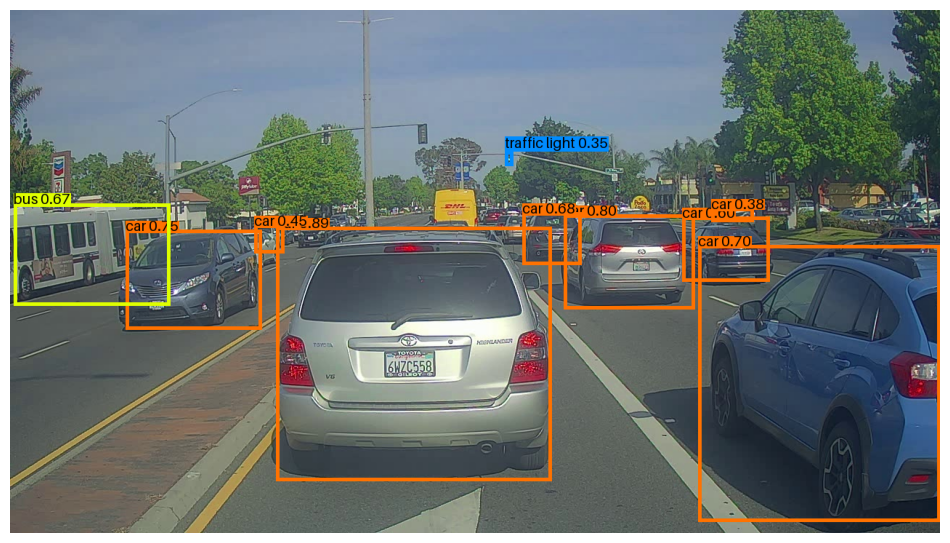

In [29]:
out_scores, out_boxes, out_classes = predict("test.jpg")

**Expected output (on the provided `test.jpg`)** — about 10 boxes, mostly cars, plus a bus and a traffic light, for example:
```
Found 10 boxes for test.jpg
car 0.89 (367, 300) (745, 648)
car 0.80 (761, 282) (942, 412)
car 0.74 (159, 303) (346, 440)
...
```
Small differences in the last digit are normal.

---
## Step 7 — Tune and test your detector

A real perception module must be tuned. Use the cells below to explore.

**7.1 — Score threshold.** Run `predict` with `score_threshold` = 0.1, 0.3 and 0.6. Count the boxes each time.


===== score_threshold = 0.1 =====
Found 10 boxes for test.jpg
car 0.89 (366, 299) (745, 648)
car 0.80 (762, 282) (942, 412)
car 0.75 (159, 303) (346, 440)
car 0.70 (947, 324) (1280, 704)
car 0.68 (705, 279) (786, 351)
bus 0.67 (5, 267) (220, 407)
car 0.60 (925, 285) (1045, 374)
car 0.45 (336, 296) (377, 335)
car 0.38 (965, 273) (1023, 292)
traffic light 0.35 (681, 195) (692, 215)


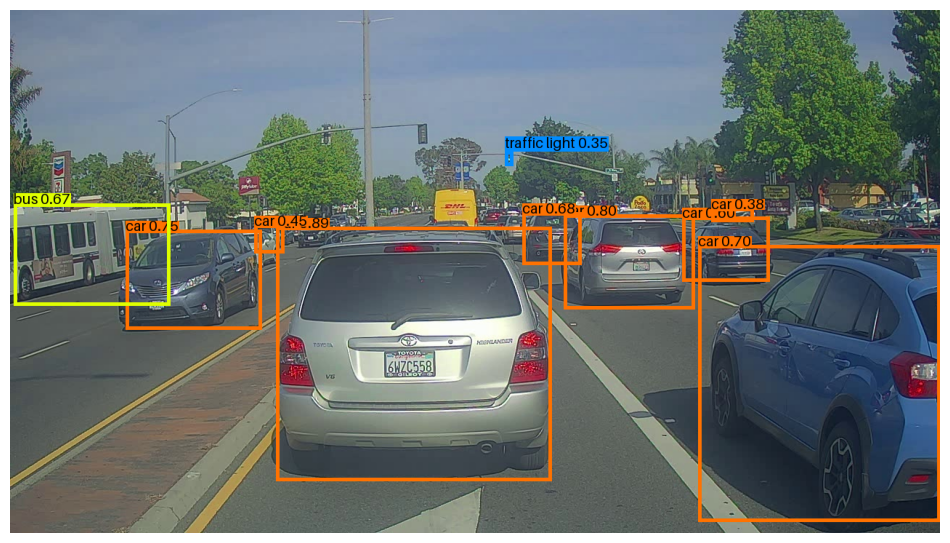


===== score_threshold = 0.3 =====
Found 10 boxes for test.jpg
car 0.89 (366, 299) (745, 648)
car 0.80 (762, 282) (942, 412)
car 0.75 (159, 303) (346, 440)
car 0.70 (947, 324) (1280, 704)
car 0.68 (705, 279) (786, 351)
bus 0.67 (5, 267) (220, 407)
car 0.60 (925, 285) (1045, 374)
car 0.45 (336, 296) (377, 335)
car 0.38 (965, 273) (1023, 292)
traffic light 0.35 (681, 195) (692, 215)


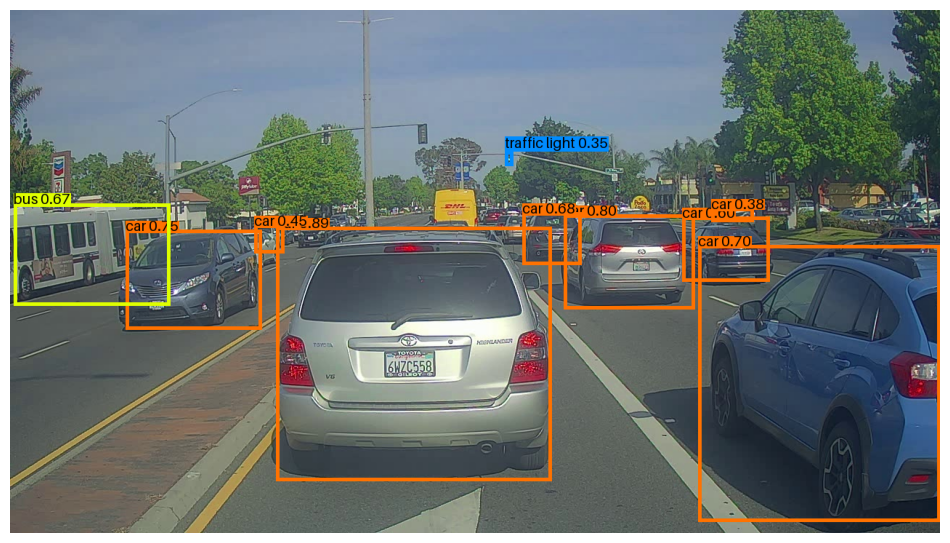


===== score_threshold = 0.6 =====
Found 7 boxes for test.jpg
car 0.89 (366, 299) (745, 648)
car 0.80 (762, 282) (942, 412)
car 0.75 (159, 303) (346, 440)
car 0.70 (947, 324) (1280, 704)
car 0.68 (705, 279) (786, 351)
bus 0.67 (5, 267) (220, 407)
car 0.60 (925, 285) (1045, 374)


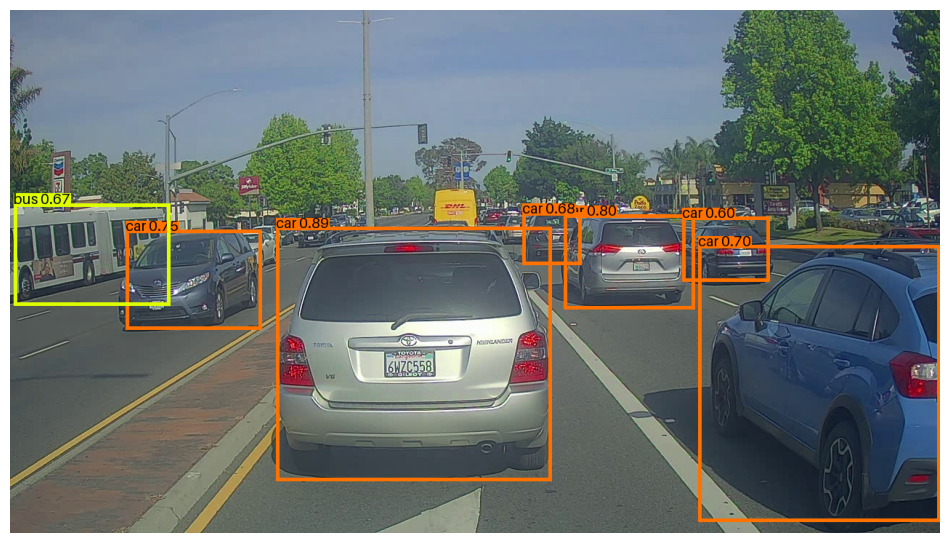

In [30]:
for th in [0.1, 0.3, 0.6]:
    print(f"\n===== score_threshold = {th} =====")
    predict("test.jpg", score_threshold=th)

**7.2 — IoU threshold.** Run `predict` with `iou_threshold` = 0.1 and 0.9 (score threshold 0.3).


===== iou_threshold = 0.1 =====
Found 10 boxes for test.jpg
car 0.89 (366, 299) (745, 648)
car 0.80 (762, 282) (942, 412)
car 0.75 (159, 303) (346, 440)
car 0.70 (947, 324) (1280, 704)
car 0.68 (705, 279) (786, 351)
bus 0.67 (5, 267) (220, 407)
car 0.60 (925, 285) (1045, 374)
car 0.45 (336, 296) (377, 335)
car 0.38 (965, 273) (1023, 292)
traffic light 0.35 (681, 195) (692, 215)


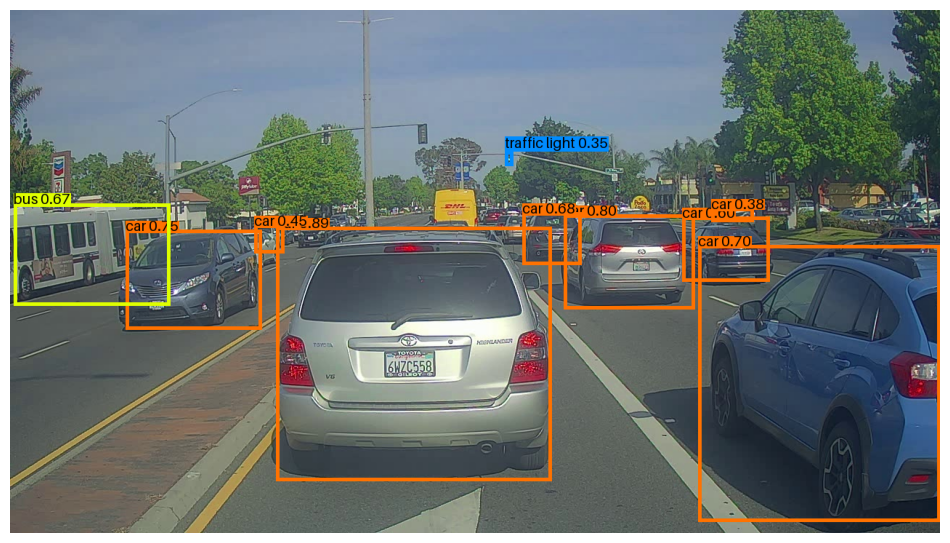


===== iou_threshold = 0.9 =====
Found 10 boxes for test.jpg
car 0.89 (366, 299) (745, 648)
car 0.80 (762, 282) (942, 412)
car 0.75 (159, 303) (346, 440)
car 0.70 (947, 324) (1280, 704)
car 0.68 (705, 279) (786, 351)
bus 0.67 (5, 267) (220, 407)
car 0.63 (755, 274) (943, 398)
car 0.60 (925, 285) (1045, 374)
car 0.54 (754, 294) (942, 401)
bus 0.53 (0, 259) (208, 441)


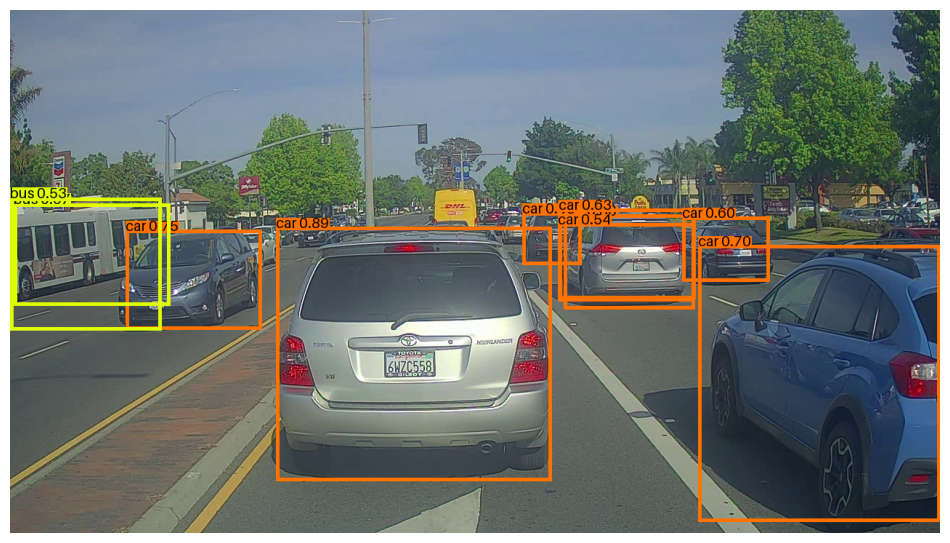

In [31]:
for th in [0.1, 0.9]:
    print(f"\n===== iou_threshold = {th} =====")
    predict("test.jpg", iou_threshold=th)

**7.3 — Your own road photo.** Upload a photo (e.g. a street in Jeddah) to `ML_Labs/Lab6/images/` and run `predict` on it.

In [32]:
# predict("my_street.jpg")

### Reflection questions (answer in this cell)
1. What did you observe when the **score threshold** was very low (0.1)? Very high (0.6)? Which is more dangerous for a self-driving car: a missed car or a false alarm? Which threshold would you choose and why?
2. What happened with **iou_threshold = 0.9**? With **0.1**? Explain using what NMS does.
3. Why can YOLO run in real time, while a sliding-window detector cannot?
4. Did the model miss anything on your own photo? Give one reason why.

*Your answers:*

1)  At 0.1, many more boxes appeared, including weak and wrong ones (false alarms). At 0.6, only a few very confident boxes were left, and some real cars were missed.

- For a self-driving car, a missed car is more dangerous, because the car could crash into it. A false alarm only makes the car brake unnecessarily.

- I would choose a lowish threshold of about 0.3. It catches most real objects without too many false alarms.

2) At 0.9, NMS only removes boxes that overlap almost completely, so duplicate boxes stayed on the same car.

- At 0.1, NMS removes boxes even with a small overlap, so cars close to each other were merged, and some real cars were lost.

- This happens because NMS keeps the best box and deletes same-class boxes whose IoU is above the threshold. A high threshold deletes too little, and a low threshold deletes too much.

3) YOLO looks at the image once. A single forward pass of the CNN predicts all 1805 boxes at the same time.

---
## Summary — what you should remember
- YOLO is a fast and accurate object detector: **one forward pass** of a CNN for the whole image.
- The output is a **19 × 19 × 5 × 85** volume: each of the 19 × 19 grid cells predicts 5 boxes (one per anchor), and each box has 5 numbers $(p_c, b_x, b_y, b_h, b_w)$ + 80 class probabilities.
- The 1805 raw boxes are filtered in two steps:
  1. **Score thresholding** — keep boxes whose class score $p_c \times c_i$ is high enough.
  2. **Non-max suppression** — for each class, keep the best box and remove boxes that overlap it with **IoU** ≥ threshold.
- Training YOLO from scratch needs a large labelled dataset and a lot of computation, so we used pre-trained weights. Fine-tuning them on your own dataset is possible but non-trivial.

## References
- J. Redmon, S. Divvala, R. Girshick, A. Farhadi — *You Only Look Once: Unified, Real-Time Object Detection*, 2016. https://arxiv.org/abs/1506.02640
- J. Redmon, A. Farhadi — *YOLO9000: Better, Faster, Stronger*, 2017. https://arxiv.org/abs/1612.08242
- A. Zelener — *YAD2K: Yet Another Darknet 2 Keras* (weight conversion). https://github.com/allanzelener/YAD2K
- Road images: The Drive.ai Sample Dataset, licensed under CC BY 4.0.